# Bloque 4. Construcción de la serie temporal

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alvaroparedesl/geomatica-aplicada/blob/main/talleres/fair-series-temporales/04_series_temporales.ipynb) [![Licencia: GPL-3.0](https://img.shields.io/badge/licencia-GPL--3.0-blue.svg)](https://github.com/alvaroparedesl/geomatica-aplicada/blob/main/LICENSE) [![Python 3.13](https://img.shields.io/badge/python-3.13-blue.svg)](https://colab.research.google.com/)

Taller *Datos FAIR, series temporales satelitales y detección de anomalías con Python*. Día 1, tarde (unos 90 minutos).

Hasta ahora trabajaste con **una** imagen. Una serie temporal es lo mismo repetido en el tiempo: el valor de una variable en un punto, fecha tras fecha. En este bloque construyes esa serie desde cero con Sentinel-2, la guardas con sus metadatos (el momento FAIR del día) y la miras.

**Qué vas a hacer**

| Parte | Tema | Minutos |
|---|---|---|
| 1 | De una imagen a una serie: revisita y nubes | 15 |
| 2 | Los puntos de muestreo (CSV) y su mapa | 15 |
| 3 | Búsqueda y carga de ventanas pequeñas (patrón nativo) | 20 |
| 4 | Máscara SCL, reflectancia e índices, paso a paso | 10 |
| 5 | La serie de todos los puntos | 5 |
| 6 | Filtro de escena frente a máscara SCL: lo medimos | 10 |
| 7 | Guardar en parquet con metadatos (FAIR) | 5 |
| 8 | La serie de 12 meses de respaldo y su gráfico | 10 |

Seguimos el **patrón nativo** del curso: la búsqueda (`pystac_client`) y la carga (`odc.stac.load`) las escribes tú. Los helpers de `utils/` solo **preparan** sus argumentos y ordenan los datos antes y después.

## Preparar el entorno

La celda `Preparar entorno` clona el repositorio del curso (para usar `utils/`). La siguiente instala los paquetes de STAC que Colab no trae, solo si faltan.

In [1]:
# @title Preparar entorno (ejecutar primero)
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:  # Colab: clonar el repositorio (y actualizarlo si ya estaba)
    RAIZ = Path("/content/geomatica-aplicada")
    if not RAIZ.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/alvaroparedesl/geomatica-aplicada", str(RAIZ)], check=True)
    else:  # una sesión anterior ya lo clonó: traer lo nuevo para no usar código viejo
        subprocess.run(["git", "-C", str(RAIZ), "pull", "-q", "--ff-only"], check=False)
else:  # Local: subir desde la carpeta actual hasta encontrar utils/
    RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils").is_dir())
sys.path.insert(0, str(RAIZ))
DATOS = RAIZ / "talleres" / "fair-series-temporales" / "datos"  # carpeta con los archivos de datos del taller

In [2]:
# @title Instalar los paquetes de este bloque (solo si faltan)
import importlib.util

# Paquete de requirements.txt -> nombre con el que se importa
NECESARIOS = {"pystac-client": "pystac_client", "planetary-computer": "planetary_computer",
              "odc-stac": "odc.stac", "rioxarray": "rioxarray"}
requisitos = [linea.strip() for linea in (RAIZ / "talleres/fair-series-temporales/requirements.txt").read_text().splitlines()
              if linea.strip() and not linea.startswith("#")]
requisitos = [r for r in requisitos if r.split()[0] in NECESARIOS]

if any(importlib.util.find_spec(modulo) is None for modulo in NECESARIOS.values()):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *requisitos], check=True)
    print("Instalado:", ", ".join(requisitos))
else:
    print("Ya está todo instalado:", ", ".join(NECESARIOS))

Instalado: pystac-client, planetary-computer, odc-stac, rioxarray


In [3]:
# @title Importar bibliotecas
import math
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import odc.stac
import pandas as pd
import planetary_computer
import plotly.express as px
import pyarrow.parquet as pq
import pystac_client
import xarray as xr
from matplotlib.colors import ListedColormap
from shapely.geometry import box, shape

# Funciones de apoyo del curso (carpeta utils/)
from utils.series import (agregar_nubes_escena, bbox_punto, bbox_puntos, cargar_puntos_csv, cargar_ventanas,
                          construir_series, crs_utm, guardar_series, resumen_validez)
from utils.stac import parametros_busqueda, parametros_carga, preparar_items, resumir_imagenes
from utils.viz import mapa_puntos

warnings.filterwarnings("ignore", category=UserWarning)  # avisos de GDAL por escenas sin georreferencia

# Una paleta distinguible con daltonismo (Okabe-Ito), una por punto
PALETA = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9"]

## Dos funciones para pasar de DN a reflectancia

En el bloque 3 convertiste a mano una imagen: `reflectancia = DN * 0,0001 + offset`, con el offset según el baseline de la imagen. Aquí hay muchas fechas, cada una con su baseline, así que dejamos esos pasos en dos funciones **escritas aquí**, para que puedas leerlas (y cambiarlas). Sirven solo para Sentinel-2 de Planetary Computer.

In [6]:
def agregar_offset(datos, items):
    # El offset depende del baseline de procesamiento de cada imagen, que está en sus metadatos:
    # baseline 04.00 o posterior -> -0.1 (a los DN se les sumaron 1000); anterior -> 0
    offset_por_fecha = {}
    for item in items:
        fecha = np.datetime64(item.datetime.replace(tzinfo=None), "ns")
        baseline = float(item.properties["s2:processing_baseline"])  # "05.11" -> 5.11
        offset_por_fecha[fecha] = -0.1 if baseline >= 4.0 else 0.0
    # La fecha de cada capa de `datos` es la de la primera imagen de su grupo: ahí buscamos su offset
    offsets = [offset_por_fecha[fecha] for fecha in datos["time"].values.astype("datetime64[ns]")]
    return datos.assign_coords(offset_reflectancia=("time", offsets))


def reflectancia_sentinel2(datos):
    # Convierte antes de combinar fechas (por ejemplo antes de .median("time")): después ya no hay un offset por fecha
    # reflectancia = DN * 0.0001 + offset de cada fecha (el DN 0 significa "sin dato")
    refl = datos.where(datos != 0) * 0.0001 + datos["offset_reflectancia"]
    # Una reflectancia válida está entre 0 y 1: lo demás pasa a NaN
    refl = refl.where((refl >= 0) & (refl <= 1))
    return refl.drop_vars("offset_reflectancia")

## 1. De una imagen a una serie temporal

Tres ideas explican casi todo lo que viene.

**Revisita.** Sentinel-2 vuelve a pasar por el mismo lugar cada pocos días (con tres satélites en órbita y escenas que se traslapan, en Concepción hay una toma cada dos o tres días). Cada toma es una **fecha** de la serie. Las fechas no son regulares ni diarias, y eso importa al calcular promedios móviles (bloque 5).

**Nubes.** Una serie con nubes mezcladas es una serie equivocada: una nube es blanca y hace que el agua parezca otra cosa. Hay dos formas de tratarlas, y no hacen lo mismo:

| | Filtro de escena (`eo:cloud_cover`) | Máscara de píxel (banda SCL) |
|---|---|---|
| Dónde actúa | En la búsqueda STAC, antes de cargar | Después de cargar, píxel por píxel |
| Qué descarta | Fechas completas | Píxeles con nube, sombra, cirrus, saturados o sin dato |
| Qué sabe de tu punto | Nada: es el porcentaje de **toda la escena** (unos 100 x 100 km) | Todo: mira justo tus píxeles |
| Costo | Ahorra datos descargados | Hay que cargar la fecha para poder juzgarla |

Más abajo medimos cuánto cambia cada una en nuestros puntos.

**Puntos y ventanas.** Cargar el área completa que encierra todos los puntos es mucho más pesado que cargar una **ventana pequeña** (unos 300 x 300 m) alrededor de cada uno. Para series en puntos, la ventana alcanza: de cada fecha resumimos sus píxeles con la mediana, que resiste algún píxel raro.

## 2. Los puntos de muestreo

Los puntos están en un archivo CSV con las columnas `id, nombre, lat, lon, tipo`. `cargar_puntos_csv` lo lee y valida (columnas, `id` únicos, rangos de latitud y longitud). Un nombre simple busca el archivo en la carpeta `datos/` del taller.

In [7]:
puntos=cargar_puntos_csv("puntos_conguillio.csv")
puntos

,id,nombre,lat,lon,tipo
0,Río_Trufu_Truful,Rio Trufu Truful,-38.812240,-71.644337,Rio
1,Laguna_Conguillio,Laguna Conguillio,-38.633175,-71.642513,Laguna
2,Volcan_Pichi_Llaima,Volcan Pichi Llaima,-38.696805,-71.729591,Volcan
3,Laguna_Verde,Laguna verde,-38.687491,-71.607212,Laguna
4,Malipeuco,Malipeuco,-38.852351,-71.684972,Descampado


In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Seis puntos: cuatro de agua (bahía de Concepción, bahía San Vicente, pluma del Biobío y golfo de Arauco), una laguna (Laguna Grande de San Pedro) y un humedal (Rocuant-Andalién) para tener también vegetación. Los miramos en un mapa. El círculo de cada punto es el radio de 150 m que usaremos para resumir cada fecha.

In [7]:
mapa_puntos(puntos, radio_m=150)

> **Opcional: QGIS.** QGIS es solo un apoyo; todo el análisis se hace aquí, en Colab. Si lo tienes instalado puedes:
>
> 1. Abrir `puntos_concepcion.geojson` (carpeta `talleres/fair-series-temporales/datos/` del repositorio) con *Capa > Añadir capa > Añadir capa vectorial*.
> 2. Editar o agregar puntos: activa la edición de la capa, usa *Añadir punto* y completa `id` (sin espacios ni repetidos), `nombre`, `tipo` y las coordenadas `lat` y `lon` en grados decimales.
> 3. Exportar a CSV: clic derecho en la capa, *Exportar > Guardar objetos como...*, formato CSV, codificación UTF-8 y, en las opciones de la capa, `GEOMETRY = AS_XY` (así se agregan las columnas de coordenadas; renómbralas a `lon` y `lat` si hace falta). El archivo debe tener exactamente las columnas `id, nombre, lat, lon, tipo`.
> 4. Subir el CSV a Colab (panel de archivos de la izquierda) y leerlo con `cargar_puntos_csv("/content/mis_puntos.csv")`.
>
> Con QGIS también puedes mirar una o dos imágenes Sentinel-2 (por ejemplo con el complemento de STAC), pero el cubo de datos lo seguimos construyendo en Colab.

**Tu turno 1.** Agrega un séptimo punto con `pd.concat` (por ejemplo, la desembocadura del río Andalién o un punto de tu interés en el golfo) y míralo en el mapa. Usa otro nombre de variable (`mis_puntos`) para no alterar el resto del cuaderno. `cargar_puntos_csv` no valida un DataFrame, solo un CSV: revisa tú que `lat` y `lon` no estén invertidas (en Concepción, `lat` es cercana a -36,8 y `lon` a -73).

In [8]:
# Tu turno 1: escribe aquí tu punto nuevo
# nuevo = pd.DataFrame([{"id": "...", "nombre": "...", "lat": ..., "lon": ..., "tipo": "..."}])
# mis_puntos = pd.concat([puntos, nuevo], ignore_index=True)
# mapa_puntos(mis_puntos, radio_m=150)

## 3. Búsqueda y carga de ventanas pequeñas

Usamos un **período corto**, de tres meses (junio a agosto de 2026, invierno), para que todo corra en pocos minutos. Es además la época más nublada: buena para estudiar las nubes. Más adelante cargamos la serie de 12 meses, que ya está preparada.

### 3.1 Búsqueda (nativa)

Hacemos **una sola búsqueda para toda la zona**: `bbox_puntos` entrega el rectángulo que contiene las ventanas de todos los puntos. Después, cada punto se queda con las imágenes que lo tocan (una escena puede cubrir unos puntos y otros no). Pedimos hasta 100 % de nubes a propósito: así podemos comparar después distintos filtros de escena con una sola carga.

In [9]:
FECHAS = ("2017-12-01", "2026-03-31")
RADIO_M = 150  # ventana de unos 300 x 300 m alrededor de cada punto

bbox = bbox_puntos(puntos, RADIO_M)
print("bbox de la zona (oeste, sur, este, norte):", [round(c, 3) for c in bbox])

# Catálogo STAC de Planetary Computer; `sign_inplace` firma los enlaces de descarga de cada imagen
catalogo = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=planetary_computer.sign_inplace)
parametros = parametros_busqueda("sentinel-2", bbox, FECHAS, nubes_max=100, catalogo=catalogo)
busqueda = catalogo.search(**parametros)  # llamada nativa de pystac_client
items = busqueda.item_collection()
items = preparar_items(items)  # sin versiones duplicadas y de un solo catálogo
print(f"{len(items)} imágenes (escenas) entre {FECHAS[0]} y {FECHAS[1]}")

bbox de la zona (oeste, sur, este, norte): [-71.731, -38.854, -71.605, -38.632]
Se encontraron 4803 imágenes (sentinel-2-l2a, planetary) (609 versiones repetidas descartadas).
4803 imágenes (escenas) entre 2017-12-01 y 2026-03-31


Cada fila es una escena (un *tile* en una fecha). Dos tiles contiguos (T18HXD y T18HXE) tomados el mismo día son dos imágenes, pero para el mismo punto solo una de ellas lo cubre. Fíjate en el baseline y el offset: el offset de reflectancia depende de la versión de procesamiento de **cada** imagen y no se fija a mano (bloque 2).

In [10]:
tabla_items = resumir_imagenes(items)
print(tabla_items.head(8).to_string())
print("\nBaselines:", tabla_items["baseline"].value_counts().to_dict(), "| offsets:", tabla_items["offset"].value_counts().to_dict())

        fecha    nubes_%                                                      id baseline  offset
0  2017-12-05   2.935647  S2A_MSIL2A_20171205T143751_R096_T18HYB_20201014T120705    02.12     0.0
1  2017-12-05   3.171549  S2A_MSIL2A_20171205T143751_R096_T18HYC_20201014T120651    02.12     0.0
2  2017-12-05   2.615368  S2A_MSIL2A_20171205T143751_R096_T19HBS_20201014T120628    02.12     0.0
3  2017-12-05   5.051968  S2A_MSIL2A_20171205T143751_R096_T19HBT_20201119T181914    02.12     0.0
4  2017-12-07  14.455435  S2B_MSIL2A_20171207T142839_R053_T18HYB_20201014T123825    02.12     0.0
5  2017-12-07   0.429440  S2B_MSIL2A_20171207T142839_R053_T18HYC_20201014T123821    02.12     0.0
6  2017-12-07  11.300899  S2B_MSIL2A_20171207T142839_R053_T19HBS_20201014T123829    02.12     0.0
7  2017-12-07   0.384842  S2B_MSIL2A_20171207T142839_R053_T19HBT_20201014T123827    02.12     0.0

Baselines: {'02.12': 1986, '05.11': 986, '05.10': 947, '04.00': 405, '03.00': 275, '05.09': 104, '05.12': 100} | offs

¿Cuántas imágenes nos quedarían con cada límite de nubes de escena? Ese filtro actúa en la búsqueda y es lo más barato, pero recuerda que dice algo de toda la escena, no de tu punto.

In [11]:
nubes = tabla_items["nubes_%"]
print(pd.Series({f"nubes <= {limite} %": int((nubes <= limite).sum()) for limite in (10, 30, 60, 100)}).to_string())

nubes <= 10 %     1532
nubes <= 30 %     2178
nubes <= 60 %     2909
nubes <= 100 %    4803


### 3.2 Carga de una ventana (nativa), a la vista

Primero un solo punto, con cada paso escrito. La carga de `odc.stac.load` es **perezosa**: arma el cubo pero todavía no lee píxeles. Así vemos su tamaño antes de pagar el tiempo de la lectura.

In [12]:
punto = puntos.loc[puntos["id"] == "Laguna_Conguillio"].iloc[0]
bbox_p = bbox_punto(punto["lon"], punto["lat"], RADIO_M)  # ventana de unos 300 x 300 m
# Solo las escenas cuya huella toca la ventana (una escena puede cubrir unos puntos y otros no)
ventana_p = box(*bbox_p)
items_p = [item for item in items if shape(item.geometry).intersects(ventana_p)]
bandas = ["B03", "B04", "B05", "B08", "SCL"]  # verde, rojo, borde rojo, NIR y la banda de clasificación (SCL)
print("Bandas:", bandas)

parametros_ds = parametros_carga("sentinel-2", bandas, resolucion=10, crs=crs_utm(punto["lon"], punto["lat"]),
                                 catalogo=catalogo, bbox=bbox_p, chunks={"x": 512, "y": 512})
datos_p = odc.stac.load(items_p, **parametros_ds)  # llamada nativa de odc.stac (perezosa)
datos_p = agregar_offset(datos_p, items_p)  # offset de reflectancia de cada fecha (la función de arriba)
datos_p = agregar_nubes_escena(datos_p, items_p)  # % de nubes de la escena de cada fecha
print(f"{len(items_p)} imágenes -> {datos_p.sizes['time']} fechas, ventana de {datos_p.sizes['x']} x {datos_p.sizes['y']} píxeles")
print(f"Tamaño del cubo de este punto: {datos_p.nbytes / 1e6:.1f} MB (todavía sin leer)")
datos_p

Bandas: ['B03', 'B04', 'B05', 'B08', 'SCL']
2403 imágenes -> 1188 fechas, ventana de 31 x 31 píxeles
Tamaño del cubo de este punto: 22.9 MB (todavía sin leer)


<xarray.Dataset> Size: 23MB
Dimensions:              (y: 31, x: 31, time: 1188)
Coordinates:
  * y                    (y) float64 248B 5.721e+06 5.721e+06 ... 5.72e+06
  * x                    (x) float64 248B 2.698e+05 2.698e+05 ... 2.701e+05
  * time                 (time) datetime64[ns] 10kB 2017-12-05T14:37:51.02600...
    offset_reflectancia  (time) float64 10kB 0.0 0.0 0.0 0.0 ... -0.1 -0.1 -0.1
    nubes_escena         (time) float64 10kB 4.112 0.4071 ... 0.1833 0.0004255
    spatial_ref          int32 4B 32719
Data variables:
    B03                  (time, y, x) float32 5MB dask.array<chunksize=(1, 31, 31), meta=np.ndarray>
    B04                  (time, y, x) float32 5MB dask.array<chunksize=(1, 31, 31), meta=np.ndarray>
    B05                  (time, y, x) float32 5MB dask.array<chunksize=(1, 31, 31), meta=np.ndarray>
    B08                  (time, y, x) float32 5MB dask.array<chunksize=(1, 31, 31), meta=np.ndarray>
    SCL                  (time, y, x) float32 5MB dask.array<chunksize=(1, 31, 31), meta=np.ndarray>

Compara con lo que pesaría cargar **toda la caja** que contiene los seis puntos, con las mismas bandas y fechas. Es solo una cuenta (ancho x alto de la caja en píxeles de 10 m):

In [13]:
lat_media = (bbox[1] + bbox[3]) / 2
ancho_m = (bbox[2] - bbox[0]) * 111_320 * math.cos(math.radians(lat_media))
alto_m = (bbox[3] - bbox[1]) * 111_320
pixeles_caja = (ancho_m / 10) * (alto_m / 10)
gb_caja = pixeles_caja * len(bandas) * datos_p.sizes["time"] * 4 / 1e9
mb_ventanas = len(puntos) * datos_p.nbytes / 1e6
print(f"Caja completa ({ancho_m / 1000:.0f} x {alto_m / 1000:.0f} km): unos {gb_caja:.0f} GB")
print(f"Seis ventanas de 300 x 300 m: unos {mb_ventanas:.0f} MB")

Caja completa (11 x 25 km): unos 64 GB
Seis ventanas de 300 x 300 m: unos 114 MB


Por eso cargamos ventanas. `cargar_ventanas` repite para **cada** punto los pasos que acabas de ver (`bbox_punto`, el filtro de escenas con `shape(...).intersects`, `parametros_carga`, `odc.stac.load`, `agregar_offset`, `agregar_nubes_escena`; usa la versión de `utils`, que hace lo mismo que la tuya) y al final lee todos los píxeles de una vez, en paralelo. Lanza la celda y espera un par de minutos: es la lectura de red de las seis ventanas.

> En una prueba anterior (otra zona) las ventanas tardaron 78 s con 313 MB y la caja completa 306 s. Con los puntos de este taller, la lectura de tres meses la medimos más abajo en esta misma celda.

In [14]:
inicio = time.time()
ventanas = cargar_ventanas(items, puntos, radio_m=RADIO_M, catalogo=catalogo)  # dict {id del punto: Dataset}
print(f"Carga total (incluye armar el cubo de cada punto): {time.time() - inicio:.0f} s")

Río_Trufu_Truful: 3589 imágenes, 1192 fechas, ventana de 32 x 32 píxeles
Laguna_Conguillio: 2403 imágenes, 1188 fechas, ventana de 31 x 31 píxeles
Volcan_Pichi_Llaima: 2399 imágenes, 1188 fechas, ventana de 31 x 32 píxeles
Laguna_Verde: 2403 imágenes, 1188 fechas, ventana de 32 x 31 píxeles
Malipeuco: 4788 imágenes, 1194 fechas, ventana de 32 x 32 píxeles
Lectura terminada: 119 MB en 1445 s.
Carga total (incluye armar el cubo de cada punto): 1669 s


`ventanas` es un diccionario con un Dataset por punto, con los valores **en números digitales (DN)**, sin enmascarar ni convertir. Cada Dataset trae las coordenadas `offset_reflectancia` y `nubes_escena`, una por fecha.

In [15]:
ventana = ventanas["Laguna_Conguillio"]
print(ventana)
print("\nPrimeras fechas con su offset y las nubes de su escena:")
print(ventana[["offset_reflectancia", "nubes_escena"]].to_dataframe().head(5).to_string())

<xarray.Dataset> Size: 23MB
Dimensions:              (y: 31, x: 31, time: 1188)
Coordinates:
  * y                    (y) float64 248B 5.721e+06 5.721e+06 ... 5.72e+06
  * x                    (x) float64 248B 2.698e+05 2.698e+05 ... 2.701e+05
  * time                 (time) datetime64[ns] 10kB 2017-12-05T14:37:51.02600...
    offset_reflectancia  (time) float64 10kB 0.0 0.0 0.0 0.0 ... -0.1 -0.1 -0.1
    nubes_escena         (time) float64 10kB 4.112 0.4071 ... 0.1833 0.0004255
    spatial_ref          int32 4B 32719
Data variables:
    B03                  (time, y, x) float32 5MB 256.0 260.0 ... 1.272e+03
    B04                  (time, y, x) float32 5MB 131.0 112.0 ... 1.044e+03
    B05                  (time, y, x) float32 5MB 137.0 137.0 ... 1.023e+03
    B08                  (time, y, x) float32 5MB 110.0 105.0 ... 1.006e+03
    SCL                  (time, y, x) float32 5MB 6.0 6.0 6.0 ... 6.0 6.0 6.0

Primeras fechas con su offset y las nubes de su escena:
                     

## 4. Máscara SCL, reflectancia e índices, paso a paso

Antes de usar `construir_series`, hacemos a mano los tres pasos para un punto.

**Paso 1: la máscara SCL.** La banda SCL (*Scene Classification Layer*) asigna a cada píxel una clase (un número entero). La máscara es una pregunta por píxel: ¿su clase está en la lista de clases que descartamos? Con `isin` obtienes un valor `True` donde la respuesta es sí, y con `~` (negación) lo inviertes para quedarte con los píxeles válidos. Estas son las clases que importan (la última columna marca las que descartamos, las mismas que `construir_series` descarta por defecto):

| Código | Clase | ¿Se descarta por defecto? |
|---|---|---|
| 0 | sin datos | sí |
| 1 | saturado | sí |
| 2 | áreas oscuras | no |
| 3 | sombra de nube | sí |
| 4 | vegetación | no |
| 5 | suelo desnudo | no |
| 6 | agua | no |
| 7 | nube de probabilidad baja o sin clasificar | no |
| 8 | nube de probabilidad media | sí |
| 9 | nube de probabilidad alta | sí |
| 10 | cirrus | sí |
| 11 | nieve o hielo | no |

Miremos qué clases hay en las ventanas de nuestros puntos (porcentaje de los píxeles de las 39 fechas, con nubes de hasta 100 % en la escena):

In [16]:
clases = {0: "sin datos", 1: "saturado", 2: "áreas oscuras", 3: "sombra de nube", 4: "vegetación", 5: "suelo desnudo",
          6: "agua", 7: "nube prob. baja", 8: "nube prob. media", 9: "nube prob. alta", 10: "cirrus", 11: "nieve"}
conteo = {}
for id_punto, datos in ventanas.items():
    scl = datos["SCL"].values
    scl = scl[~np.isnan(scl)].astype(int)
    conteo[id_punto] = pd.Series(scl).value_counts(normalize=True).mul(100)
distribucion = pd.DataFrame(conteo).rename(index=clases).fillna(0).round(1)
distribucion.loc[distribucion.sum(axis=1) > 0]

,Río_Trufu_Truful,Laguna_Conguillio,Volcan_Pichi_Llaima,Laguna_Verde,Malipeuco
áreas oscuras,7.6,0.0,10.1,0.2,1.0
sombra de nube,1.4,0.0,1.8,0.0,1.0
vegetación,27.2,0.0,0.0,0.0,33.1
suelo desnudo,15.4,0.0,2.5,0.0,17.5
agua,0.1,57.7,1.7,57.7,0.0
nube prob. baja,6.2,0.0,2.2,0.0,2.7
nube prob. media,14.2,16.2,23.0,13.9,14.6
nube prob. alta,21.4,17.0,12.6,21.1,23.5
cirrus,5.5,7.3,0.0,6.1,5.5
nieve,1.0,1.8,46.0,0.9,1.1


Mira la fila `agua`: en invierno, en estas ventanas, solo una parte de los píxeles es agua despejada y el resto son nubes de probabilidad media o alta. Y fíjate en el humedal: tiene vegetación, suelo desnudo y sombras de nube (clases 3, 4 y 5) que en los puntos de agua casi no aparecen. La lista de clases que se descarta por defecto está pensada para vegetación y tierra; cerca del agua conviene revisar qué clases se están descartando y si tiene sentido.

Veamos las ventanas de tres fechas del punto de la bahía, de la más despejada a la más nublada **en la ventana**, con las nubes de **la escena** en el título. Fíjate que las dos cifras no siempre cuentan lo mismo.

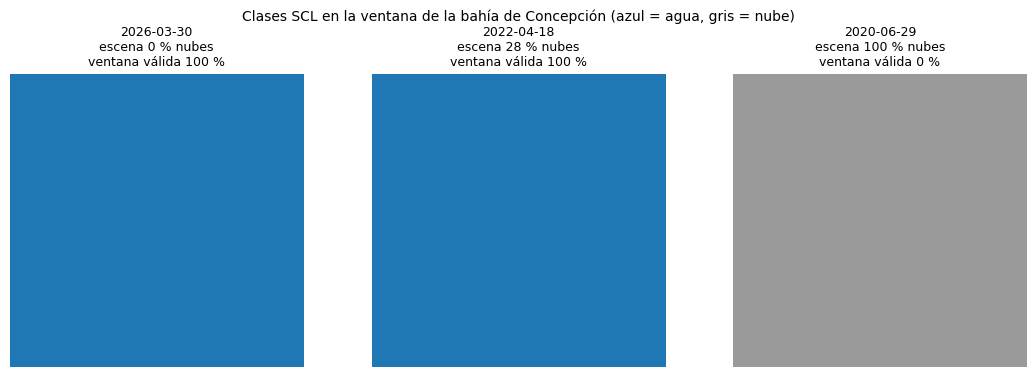

In [17]:
excluir = [0, 1, 3, 8, 9, 10]  # sin datos, saturado, sombra de nube, nube media, nube alta y cirrus (tabla de arriba)
valida = ~ventana["SCL"].isin(excluir)  # True donde el píxel es válido
fraccion_valida = valida.mean(["x", "y"]).to_series()
orden = fraccion_valida.sort_values(ascending=False)
elegidas = [orden.index[0], orden.index[len(orden) // 2], orden.index[-1]]

colores_scl = ["#000000", "#ff0000", "#4d4d4d", "#8b4513", "#33a02c", "#e6d28c", "#1f78b4", "#bdbdbd", "#9a9a9a", "#e0e0e0", "#a6cee3", "#ffffff"]
cmap_scl = ListedColormap(colores_scl)
fig, ejes = plt.subplots(1, 3, figsize=(11, 3.8))
for eje, fecha in zip(ejes, elegidas):
    imagen = ventana["SCL"].sel(time=fecha).values
    eje.imshow(imagen, cmap=cmap_scl, vmin=-0.5, vmax=11.5)
    nubes_fecha = float(ventana["nubes_escena"].sel(time=fecha))
    eje.set_title(f"{pd.Timestamp(fecha):%Y-%m-%d}\nescena {nubes_fecha:.0f} % nubes\nventana válida {100 * fraccion_valida[fecha]:.0f} %", fontsize=9)
    eje.axis("off")
plt.suptitle("Clases SCL en la ventana de la bahía de Concepción (azul = agua, gris = nube)", fontsize=10)
plt.tight_layout()
plt.show()

**Paso 2: aplicar la máscara y convertir a reflectancia.** Los píxeles inválidos pasan a NaN. Luego `reflectancia_sentinel2` aplica `DN * 0.0001 + offset`, con el offset de **cada fecha** (la coordenada `offset_reflectancia`). Por eso se convierte **antes** de combinar fechas.

**Paso 3: los índices.** Con la reflectancia calculamos, con aritmética de bandas (cada banda es un `DataArray` y se opera directamente): NDWI de McFeeters (agua, `(B03 - B08) / (B03 + B08)`), NDCI (clorofila, `(B05 - B04) / (B05 + B04)`), NDVI (vegetación, `(B08 - B04) / (B08 + B04)`) y la reflectancia roja B04 (turbidez), que se usa tal cual. Una reflectancia válida es mayor o igual que 0, así que cada índice queda entre -1 y 1; si en un píxel ambas bandas valen 0 la división es 0 / 0 y el resultado es NaN.

In [18]:
espectrales = ventana[["B03", "B04", "B05", "B08"]]
enmascarada = espectrales.where(valida)  # píxeles con nube, sombra, cirrus o sin dato -> NaN
refl = reflectancia_sentinel2(enmascarada)  # DN * 0.0001 + offset de cada fecha
indices = xr.Dataset({
    "NDWI_AGUA": (refl["B03"] - refl["B08"]) / (refl["B03"] + refl["B08"]),  # verde y NIR
    "NDCI": (refl["B05"] - refl["B04"]) / (refl["B05"] + refl["B04"]),  # borde rojo y rojo
    "NDVI": (refl["B08"] - refl["B04"]) / (refl["B08"] + refl["B04"]),  # NIR y rojo
    "B04": refl["B04"],  # reflectancia roja
})
print("Variables:", list(indices.data_vars))
print(f"Reflectancia roja de la ventana, fecha más despejada: mediana {float(refl['B04'].sel(time=elegidas[0]).median()):.4f}")

Variables: ['NDWI_AGUA', 'NDCI', 'NDVI', 'B04']
Reflectancia roja de la ventana, fecha más despejada: mediana 0.0055


Una fecha, un número: la **mediana de la ventana** (los píxeles dentro de los 150 m del punto que no están enmascarados). Si menos de la mitad de la ventana quedó libre de nubes, la fecha se conserva pero su valor queda en NaN, para que el hueco se vea.

## 5. La serie de todos los puntos

`construir_series` hace estos mismos pasos para los seis puntos y entrega una **tabla ancha**: una fila por punto y fecha.

* `ndwi`, `ndci`, `b04` y `ndvi`: la mediana de la ventana.
* `nubes_escena`: las nubes de la escena completa (el filtro del catálogo).
* `pixeles_validos`: la fracción de la ventana que pasó la máscara SCL (lo que pasa en **tu** punto).
* `offset_reflectancia`: el offset aplicado a esa fecha.

In [19]:
serie = construir_series(ventanas, puntos, radio_m=RADIO_M, fraccion_minima=0.5)
print(f"{len(serie)} filas, {serie['fecha'].nunique()} fechas distintas")
serie.head(8)

5950 filas, 1194 fechas distintas


,id,nombre,tipo,lat,lon,fecha,ndwi,ndci,b04,ndvi,nubes_escena,pixeles_validos,n_pixeles,offset_reflectancia
0,Laguna_Conguillio,Laguna Conguillio,Laguna,-38.633175,-71.642513,2017-12-05 14:37:51.026,0.555556,0.017341,0.0082,-0.135484,4.111758,1.0,705,0.0
1,Laguna_Conguillio,Laguna Conguillio,Laguna,-38.633175,-71.642513,2017-12-07 14:28:39.027,0.984496,-0.166667,0.0016,-0.857143,0.407141,1.0,705,0.0
2,Laguna_Conguillio,Laguna Conguillio,Laguna,-38.633175,-71.642513,2017-12-10 14:37:39.027,0.390029,0.014706,0.0101,-0.010638,0.823451,1.0,705,0.0
3,Laguna_Conguillio,Laguna Conguillio,Laguna,-38.633175,-71.642513,2017-12-12 14:27:51.026,NaN,NaN,NaN,NaN,92.601205,0.0,705,0.0
4,Laguna_Conguillio,Laguna Conguillio,Laguna,-38.633175,-71.642513,2017-12-17 14:28:39.027,0.983333,-0.133333,0.0012,-0.846154,0.193009,1.0,705,0.0
5,Laguna_Conguillio,Laguna Conguillio,Laguna,-38.633175,-71.642513,2017-12-20 14:37:39.027,NaN,NaN,NaN,NaN,54.784165,0.0,705,0.0
6,Laguna_Conguillio,Laguna Conguillio,Laguna,-38.633175,-71.642513,2017-12-25 14:37:51.026,0.224880,0.014851,0.0194,-0.006897,9.211177,1.0,705,0.0
7,Laguna_Conguillio,Laguna Conguillio,Laguna,-38.633175,-71.642513,2017-12-27 14:28:49.027,0.612565,-0.010204,0.0046,-0.119497,0.178310,1.0,705,0.0


`resumen_validez` cuenta, por punto, las fechas con cobertura y las fechas que aportan un valor útil:

In [ ]:
resumen_validez(serie)

## 6. Filtro de escena frente a máscara SCL: lo medimos

Con una sola carga (de hasta 100 % de nubes) podemos simular cuatro límites de nubes de escena, **con** y **sin** máscara SCL. Para "sin máscara" volvemos a llamar a `construir_series` con `excluir=[]` (no se descarta ninguna clase SCL; solo se quitan los píxeles sin dato).

Contamos las **fechas válidas** (con NDWI calculado) sumando los seis puntos.

In [20]:
sin_scl = construir_series(ventanas, puntos, radio_m=RADIO_M, fraccion_minima=0.5, excluir=[])

filas = []
for limite in (100, 60, 30, 10):
    for nombre, tabla in (("sin máscara SCL", sin_scl), ("con máscara SCL", serie)):
        sub = tabla[tabla["nubes_escena"] <= limite]
        filas.append({"límite de nubes de escena (%)": limite, "máscara": nombre,
                      "fechas": len(sub), "fechas válidas": int(sub["ndwi"].notna().sum())})
comparacion = pd.DataFrame(filas)
ancho = comparacion.pivot(index="límite de nubes de escena (%)", columns="máscara", values=["fechas", "fechas válidas"])
ancho = ancho.sort_index(ascending=False)
ancho

fechas                  fechas válidas  \
máscara                       con máscara SCL sin máscara SCL con máscara SCL   
límite de nubes de escena (%)                                                   
100                                      5950            5950            3415   
60                                       3742            3742            3085   
30                                       2799            2799            2560   
10                                       1992            1992            1862   

                                               
máscara                       sin máscara SCL  
límite de nubes de escena (%)                  
100                                      5737  
60                                       3637  
30                                       2702  
10                                       1909

Lo importante está en la diferencia entre las dos columnas de *fechas válidas*. Sin máscara casi todas las fechas parecen válidas, **incluso las nubladas**: una nube es un píxel brillante con valores "razonables", no un dato faltante. La máscara SCL reconoce esas fechas y las deja en NaN.

¿Cuántas de las fechas "válidas sin máscara" tienen en realidad más de la mitad de su ventana tapada? Son las fechas **contaminadas**: si las dejaras, entrarían nubes a tu serie.

In [21]:
unidas = sin_scl.merge(serie, on=["id", "fecha"], suffixes=("_sin", "_con"))
unidas["contaminada"] = unidas["ndwi_sin"].notna() & unidas["ndwi_con"].isna()
filas = []
for limite in (100, 60, 30, 10):
    sub = unidas[unidas["nubes_escena_sin"] <= limite]
    filas.append({"límite de nubes de escena (%)": limite,
                  "fechas válidas sin máscara": int(sub["ndwi_sin"].notna().sum()),
                  "de ellas, contaminadas": int(sub["contaminada"].sum()),
                  "% de píxeles que quita la máscara": round(100 * (1 - sub["pixeles_validos_con"].mean()), 1)})
pd.DataFrame(filas).set_index("límite de nubes de escena (%)")

,fechas válidas sin máscara,"de ellas, contaminadas",% de píxeles que quita la máscara
límite de nubes de escena (%),,,
100,5737,2322,41.099998
60,3637,552,15.100000
30,2702,142,5.500000
10,1909,47,2.800000


Así se ve la contaminación en el NDWI de los puntos de agua: las fechas contaminadas (sin máscara) se alejan de las válidas porque están midiendo nube.

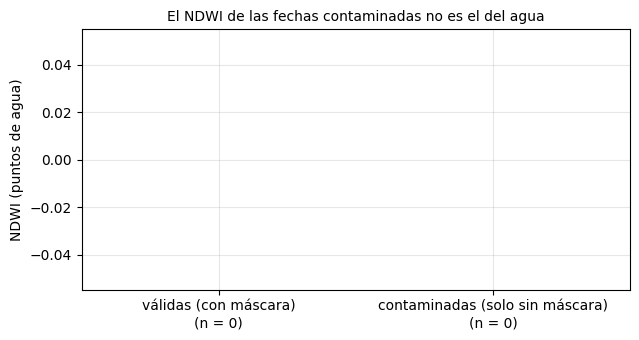

In [22]:
agua = unidas[unidas["tipo_sin"].isin(["rio", "volcan", "descampado", "laguna"])]
grupos = {"válidas (con máscara)": agua.loc[agua["ndwi_con"].notna(), "ndwi_con"],
          "contaminadas (solo sin máscara)": agua.loc[agua["contaminada"], "ndwi_sin"]}
fig, eje = plt.subplots(figsize=(6.5, 3.5))
eje.boxplot(list(grupos.values()), tick_labels=[f"{k}\n(n = {len(v)})" for k, v in grupos.items()], widths=0.5)
eje.set_ylabel("NDWI (puntos de agua)")
eje.set_title("El NDWI de las fechas contaminadas no es el del agua", fontsize=10)
eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Lectura.**

* El **filtro de escena** descarta fechas completas y es barato, pero ciego a tu punto. Con límites bajos (10 %) casi no hay fechas contaminadas, pero tampoco quedan muchas fechas: en invierno son pocas.
* La **máscara SCL** actúa píxel por píxel. Con límites altos de nubes es la que evita que la nube entre en la serie y conserva fechas despejadas en el punto aunque la escena esté nublada en otro lado.
* Usa **las dos**: un filtro de escena laxo (60 % en el respaldo) para no cargar fechas inútiles y la máscara SCL para el resto.
* Estas cifras son de tres meses de invierno. En verano las nubes son menos y la diferencia se achica.

**Tu turno 2.** Repite la comparación excluyendo además la clase 7 (nube de probabilidad baja o sin clasificar) y la 2 (áreas oscuras). Se pasan como códigos a `excluir`: la lista por defecto es `("sin_datos", "saturado", "sombra_nube", "nube_media", "nube_alta", "cirrus")` y puedes agregarle números. ¿Cambia el número de fechas válidas? ¿Qué pasa con el humedal?

In [ ]:
# Tu turno 2: una máscara más estricta
# excluir_estricta = ("sin_datos", "saturado", "sombra_nube", "nube_media", "nube_alta", "cirrus", 7, 2)
# estricta = construir_series(ventanas, puntos, radio_m=RADIO_M, fraccion_minima=0.5, excluir=excluir_estricta)
# pd.DataFrame({"por defecto": serie.groupby("id")["ndwi"].count(), "estricta": estricta.groupby("id")["ndwi"].count()})

## 7. Guardar la serie en parquet con metadatos (el momento FAIR)

Una tabla suelta en la memoria de Colab se pierde al cerrar la sesión y nadie sabe de dónde salió. En **parquet** la tabla conserva sus tipos y los **metadatos viajan dentro del mismo archivo**: título, descripción, fuente, licencia, parámetros y qué significa cada columna. Es el paso que vuelve tu serie *encontrable, accesible, interoperable y reutilizable*: este archivo es el que pasa a los bloques siguientes.

In [24]:
metadatos = {
    "titulo": f"Series temporales Sentinel-2 en puntos de agua y costa de Concepción ({FECHAS[0]} a {FECHAS[1]})",
    "descripcion": ("Mediana, en una ventana circular de 150 m de radio alrededor de cada punto, del NDWI de McFeeters (B03 y B08), "
                    "el NDCI (B05 y B04), la reflectancia roja B04 y el NDVI (B08 y B04) de Sentinel-2 L2A. Píxeles con nubes, "
                    "sombras, cirros, saturados o sin dato (SCL) descartados antes de resumir; las fechas con menos de la mitad "
                    "de la ventana válida tienen los índices en NaN."),
    "fuente": "ESA Copernicus Sentinel-2 L2A, leído como COG desde Microsoft Planetary Computer (colección sentinel-2-l2a)",
    "licencia": "Datos Copernicus Sentinel de acceso libre y abierto (Reglamento UE 1159/2013). Cita: contiene datos Copernicus Sentinel modificados (2026).",
    "periodo": f"{FECHAS[0]} a {FECHAS[1]}",
    "generado": pd.Timestamp.today().strftime("%Y-%m-%d"),
    "parametros": {"nubes_max_escena": 100, "radio_m": RADIO_M, "estadistico": "mediana", "fraccion_minima_pixeles_validos": 0.5,
                   "resolucion_m": 10, "crs": "UTM de los puntos (EPSG:32718)", "catalogo": "planetary"},
    "columnas": {
        "id": "identificador del punto", "nombre": "nombre del punto", "tipo": "tipo de cobertura",
        "lat": "latitud, grados (EPSG:4326)", "lon": "longitud, grados (EPSG:4326)", "fecha": "fecha y hora UTC de la toma",
        "ndwi": "(B03 - B08) / (B03 + B08), adimensional, positivo sobre agua",
        "ndci": "(B05 - B04) / (B05 + B04), adimensional, sube con la clorofila",
        "b04": "reflectancia roja (0 a 1), sube con la turbidez",
        "ndvi": "(B08 - B04) / (B08 + B04), adimensional",
        "nubes_escena": "% de nubes de la escena completa (eo:cloud_cover)",
        "pixeles_validos": "fracción (0 a 1) de la ventana que pasó la máscara SCL",
        "n_pixeles": "píxeles de la ventana",
        "offset_reflectancia": "offset aplicado a esa fecha (0 o -0.1), según baseline y catálogo"},
}
archivo = Path("mi_serie_sentinel2.conguillio.parquet")  # en Colab queda en /content (panel de archivos de la izquierda)
guardar_series(serie, archivo, metadatos)
print(f"Guardado: {archivo} ({archivo.stat().st_size / 1024:.0f} kB)")

Guardado: mi_serie_sentinel2.conguillio.parquet (168 kB)


Para comprobar que el archivo se entiende sin este cuaderno, léelo de vuelta junto con sus metadatos:

In [25]:
recuperada = pd.read_parquet(archivo)
# Los metadatos viajan dentro del archivo, como bytes (la clave "pandas" es de pandas y no nos interesa)
leidos = {k.decode(): v.decode() for k, v in pq.read_schema(archivo).metadata.items() if k != b"pandas"}
print(recuperada.dtypes.to_string())
print("\nMetadatos dentro del archivo:", ", ".join(leidos))
print("Título:", leidos["titulo"])

id                             object
nombre                         object
tipo                           object
lat                           float64
lon                           float64
fecha                  datetime64[ns]
ndwi                          float64
ndci                          float64
b04                           float64
ndvi                          float64
nubes_escena                  float64
pixeles_validos               float32
n_pixeles                       int64
offset_reflectancia           float64

Metadatos dentro del archivo: titulo, descripcion, fuente, licencia, periodo, generado, parametros, columnas
Título: Series temporales Sentinel-2 en puntos de agua y costa de Concepción (2017-12-01 a 2026-03-31)


**Tu turno 3.** En Colab, descarga el parquet (menú de archivos de la izquierda, clic derecho, *Descargar*) y ábrelo con otra herramienta, por ejemplo con `pandas.read_parquet` en tu computador. ¿Qué metadato agregarías para que un tercero lo pueda reutilizar sin preguntarte nada? (Una pista: el bloque 1 ya te dio la respuesta.)

## 8. La serie de 12 meses de respaldo y su gráfico

La carga de 12 meses toma más tiempo que la de tres. Para los bloques siguientes usamos la serie ya preparada con el mismo flujo, `series_sentinel2_concepcion.parquet` (octubre de 2025 a septiembre de 2026, filtro de escena de 60 %). Es también el respaldo si la carga en vivo falla.

Antes de usarla, una prueba de **reproducibilidad**: las fechas que ambos tienen en común (junio a agosto de 2026, hasta 60 % de nubes de escena) deberían tener exactamente los mismos valores.

In [26]:
respaldo = pd.read_parquet(DATOS / "mi_serie_sentinel2.conguillio.parquet")
print(f"Respaldo: {len(respaldo)} filas, {respaldo['fecha'].min():%Y-%m-%d} a {respaldo['fecha'].max():%Y-%m-%d}")

variables = ["ndwi", "ndci", "b04", "ndvi", "pixeles_validos"]
nuestra = serie[serie["nubes_escena"] <= 60].set_index(["id", "fecha"]).sort_index()
suya = respaldo[(respaldo["fecha"] >= FECHAS[0]) & (respaldo["fecha"] <= f"{FECHAS[1]} 23:59")].set_index(["id", "fecha"]).sort_index()
comunes = nuestra.index.intersection(suya.index)
diferencia = (nuestra.loc[comunes, variables] - suya.loc[comunes, variables]).abs().max()
print(f"Filas en común: {len(comunes)} (nuestra: {len(nuestra)}, respaldo: {len(suya)})")
print("Diferencia máxima por variable:", diferencia.round(6).to_dict())

Respaldo: 255 filas, 2025-12-02 a 2026-03-30
Filas en común: 193 (nuestra: 3742, respaldo: 255)
Diferencia máxima por variable: {'ndwi': 0.0, 'ndci': 0.0, 'b04': 0.0, 'ndvi': 0.0, 'pixeles_validos': 0.0}


Si la diferencia es 0, tu serie y la del respaldo son la misma: tu flujo es reproducible.

El respaldo tiene tres filas más, todas del **golfo de Arauco**. Ese punto cae donde se traslapan dos escenas el mismo día. El respaldo se buscó con un filtro de escena de 60 %, así que de cada par entró solo la escena despejada. Nosotros cargamos las dos (límite 100 %) y `nubes_escena` es el **promedio** de ambas, que en esas tres fechas pasa de 60 %. Es un ejemplo de por qué el filtro de escena depende de dónde cae tu punto, no solo del punto.

Ahora el gráfico de las cuatro variables con `plotly`: un panel por variable y un color por punto. Los marcadores son las **observaciones** (no hay datos entre ellos). Es interactivo: pasa el mouse sobre un marcador para ver su valor, haz clic en un nombre de la leyenda para ocultar o mostrar un punto, arrastra para acercar y haz doble clic para volver a la vista completa.

In [27]:
etiquetas = {"ndwi": "NDWI (agua)", "ndci": "NDCI (clorofila)", "b04": "B04, reflectancia roja (turbidez)", "ndvi": "NDVI (vegetación)"}

# plotly pide una fila por observación y variable ("formato largo"); las fechas sin valor (NaN) se omiten
largo = respaldo.melt(id_vars=["nombre", "fecha"], value_vars=list(etiquetas), var_name="variable", value_name="valor")
largo["variable"] = largo["variable"].map(etiquetas)
largo = largo.dropna(subset=["valor"])

fig = px.line(largo, x="fecha", y="valor", color="nombre", facet_row="variable", markers=True,
              category_orders={"variable": list(etiquetas.values())}, color_discrete_sequence=PALETA,
              title="Series Sentinel-2 por punto, diciembre de 2025 a marzo de 2026", height=900,
              labels={"fecha": "Fecha", "valor": "", "nombre": "Punto"})
fig.update_yaxes(matches=None)  # cada panel con su propia escala
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))  # el título de cada panel: "variable=NDWI" -> "NDWI"
fig.show()

**Cómo mirarlo.** El humedal (NDVI alto, NDWI muy negativo) separa tierra de agua. Entre los puntos de agua, la pluma del Biobío tiene la mediana de reflectancia roja más alta. En el bloque 5 medimos todo esto con números; en el 6 hacemos más gráficos interactivos.

**Tu turno 4.** Con la serie de respaldo: ¿qué punto tiene menos fechas válidas de NDWI? ¿Qué mes tiene menos fechas en total entre los seis puntos? Usa `resumen_validez(respaldo)` y `respaldo.groupby(respaldo["fecha"].dt.to_period("M")).size()`.

In [ ]:
# Tu turno 4
resumen_validez(respaldo)

## Cierre

* Una serie por punto se construye cargando **ventanas pequeñas**, no la caja completa.
* El offset de reflectancia se decide **por fecha** (`agregar_offset`); nunca se fija a mano.
* Filtro de escena y máscara SCL no son lo mismo: la máscara es la que protege tu punto. Úsalas juntas.
* El parquet con metadatos es el momento FAIR: el archivo se explica solo y pasa al bloque 5.

Entregable del día: este cuaderno con tu serie guardada en parquet.

In [ ]:
# Limpieza: borra el parquet de práctica si no lo necesitas (en Colab desaparece al cerrar la sesión)
# archivo.unlink()